# Qiskit · Quantum Africa: Moroccan crop challenge

Build a quantum or hybrid classifier for **alfalfa, maize and wheat**. Read the [student brief (PDF)](../Student_Challenge_Brief.pdf) and [installation instructions](../README.md), select your project Python kernel, then run the cells in order. All data is supplied: **914 training, 150 validation and 221 unlabeled test fields**. “Development data” means validation data.

**Your challenge:** the simple QNN currently performs worse than the classical baseline (mean validation macro-F1 **0.8557 versus 0.8797**). Improve it **or replace it with another quantum or hybrid approach**; you are not required to build on this QNN. Compare fairly and explain your findings.

The workflow is load → preprocess → fit → evaluate → investigate. The default quick fit uses 100 fixed training fields; change `USE_FULL_TRAINING` to `True` for all 914. Later plots use supplied full-training results, independently of your quick fit. The final section maps each Python file to the changes you can make.

**Data assumption:** crop labels surveyed on 23–27 April 2024 are assumed valid for imagery from 25 April (±2 calendar days); crop persistence is not independently verified. See [data notes](../data/README.md) for feature definitions and spatial splits. Keep evaluation fields fixed and use validation, never test labels, to choose settings.

In [2]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Find the supplied package whether you open this notebook from the root or notebooks/.
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'challenge/coverage.py').exists(), 'Run from the repository root or its notebooks folder'
sys.path.insert(0, str(ROOT))
from challenge.data import load_data
from challenge.coverage import LABELS
from challenge.classical import reference
from challenge.models import QuantumClassifier, MatchedHead
from challenge.metrics import score

# Figures and your quick-run results are saved here; supplied results stay unchanged.
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
def save_show(fig, name):
    fig.savefig(OUT / (name + '.png'), dpi=160, bbox_inches='tight')
    display(fig)
    plt.close(fig)

# Verify checksums, feature schemas and split IDs, then load the tables and prepared view.
tables, view, manifest, _ = load_data()
USE_FULL_TRAINING = True  # Change to True for the main 914-field comparison.
train, validation = tables['train'], tables['validation']
features = manifest['features']
assert LABELS == ['alfalfa', 'maize', 'wheat']
assert 'target' not in tables['test']
print('Classes:', LABELS)
print('Rows:', manifest['rows'])
print('Python:', sys.version.split()[0])

Classes: ['alfalfa', 'maize', 'wheat']
Rows: {'train': 914, 'validation': 150, 'test': 221}
Python: 3.12.10


## 1. Prepare inputs and inspect the data

`features` selects the 13 numerical bands/NDVI columns, excluding IDs and labels. `prep` standardizes them, reduces them to four PCA components, then standardizes those components. `A` is the training representation; `B` is validation transformed using the same fitted pipeline. No transform is fitted on validation or test.

For this quick walkthrough, preprocessing uses all 914 training fields and the models fit the fixed 100-field subset (34 alfalfa, 33 maize, 33 wheat). For a strict training-size experiment, use the coverage commands below: they refit preprocessing using only the selected subset.

**Read the plots:** the left panel shows class imbalance; the right shows the first two training-fitted components, not geographic locations. Overlap suggests that these two components alone do not separate all crops. You can replace the representation here, but update both QNN and control consistently; the current model expects four inputs.

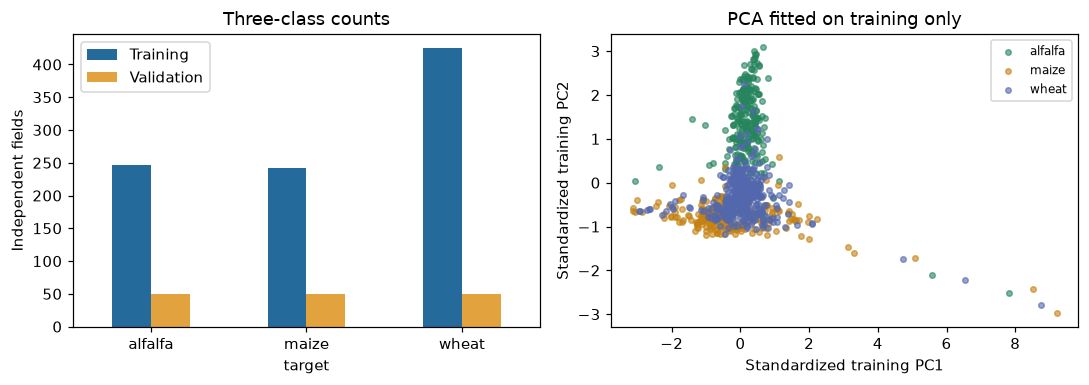

In [3]:
# Fit on training features only; reuse this object unchanged for evaluation.
prep = make_pipeline(StandardScaler(), PCA(4, svd_solver='full'), StandardScaler())
A = prep.fit_transform(train[features].to_numpy())
B = prep.transform(validation[features].to_numpy())
# Select exactly the same training fields for all three models.
starter_ids = json.loads((ROOT / 'data/starter_ids.json').read_text())
starter = train.set_index('sample_id').loc[starter_ids]
index = train.set_index('sample_id').index.get_indexer(starter_ids)
assert len(index) == 100 and (index >= 0).all()
assert set(starter.target) == set(LABELS)
if USE_FULL_TRAINING:
    index = np.arange(len(train))
    starter = train

# Inspect imbalance and the feature view before interpreting classifier scores.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
counts = pd.DataFrame({'Training': train.target.value_counts(),
                       'Validation': validation.target.value_counts()}).reindex(LABELS)
counts.plot.bar(ax=axes[0], rot=0, color=['#246a9a','#e2a33e'])
axes[0].set(ylabel='Independent fields', title='Three-class counts')
for label, color in zip(LABELS, ['#26855d','#c48214','#5267ad']):
    mask = train.target.eq(label).to_numpy()
    axes[1].scatter(A[mask, 0], A[mask, 1], label=label, s=13, alpha=.6, color=color)
axes[1].set(xlabel='Standardized training PC1', ylabel='Standardized training PC2', title='PCA fitted on training only')
axes[1].legend(fontsize=8)
fig.tight_layout(); save_show(fig, '01_data_overview')
counts.to_csv(OUT / 'class_counts.csv')

## 2. Understand or replace the model

Four prepared features become angles `(π/2) × (1 + tanh(x))`. Four RY encoding gates feed one `real_amplitudes` repetition with eight trainable angles. `QMLSampler(shots=None)` gives exact probabilities. **Outcome modulo 3** maps all 16 bitstrings into class groups of **6/5/5**, in `LABELS` order; no outcome is discarded.

The classical control is 4 → tanh(1) → softmax(3), with 11 trainable values. Its **37.5% parameter mismatch** is a limitation to report. Both branches use the same inputs and 100 COBYLA objective evaluations. Shared preprocessing stores 99 fitted coefficients; complete fitted totals are 107 (QNN) and 110 (control), counting shared values once.

**Read the outputs:** the flow diagram traces data to probabilities; the circuit distinguishes input `x` from trainable `theta`. The resource dictionary reports four qubits, depth six and three CX gates before routing. Objective evaluations are zero before fitting. Change `encoding` or `max_evals` below for a first experiment; change `make_circuit` in `challenge/models.py` for architecture changes. Keep the baseline and comparable control.

The next cell fits seed 0, checks probability normalization, row-order independence and save/reload consistency, then reports **quick-run validation** scores. Macro-F1 averages the three class F1 scores equally; accuracy counts correct fields; recall lists follow `LABELS`. Passing assertions produce no output; a failed assertion stops the cell.

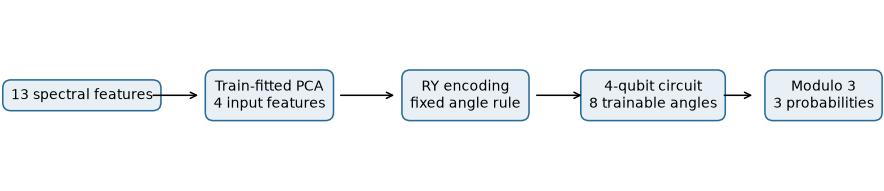

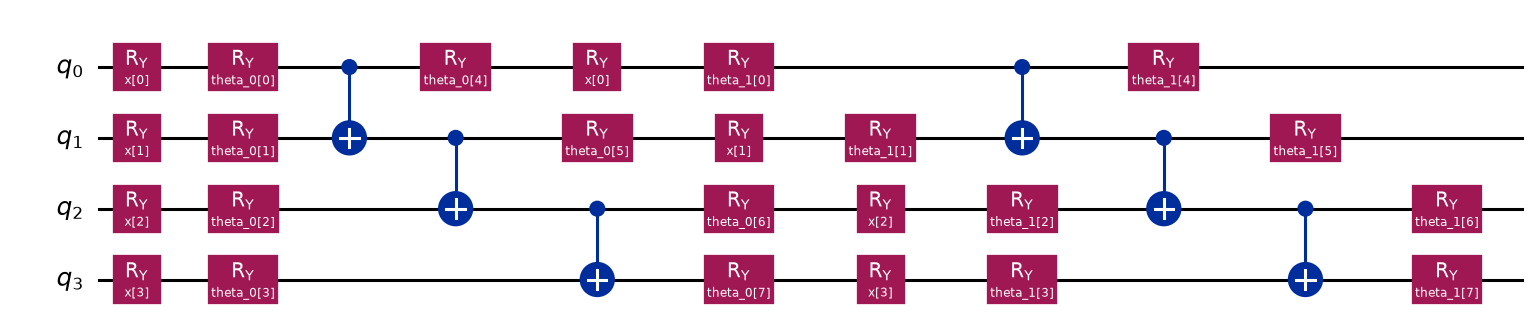

{'qubits': 4, 'reps': 2, 'trainable': 16, 'frozen_quantum': 0, 'depth': 11, 'two_qubit_gates': 6, 'objective_evaluations': 0, 'readout_group_sizes': [6, 5, 5], 'encoding': 'ry', 'compilation': 'logical decomposed H/P/RY/CX; no backend routing'}


In [4]:
# Diagram of the starter pipeline; update its labels if you replace the model.
fig, ax = plt.subplots(figsize=(10, 2))
ax.axis('off')
boxes = [(0.08, '13 spectral features'), (.30, 'Train-fitted PCA\n4 input features'),
         (.53, 'RY encoding\nfixed angle rule'), (.75, '4-qubit circuit\n8 trainable angles'),
         (.95, 'Modulo 3\n3 probabilities')]
for x, label in boxes:
    ax.text(x, .5, label, transform=ax.transAxes, ha='center', va='center', fontsize=9,
            bbox=dict(boxstyle='round,pad=.6', fc='#e8f0f5', ec='#246a9a'))
for (x, _), (next_x, _) in zip(boxes[:-1], boxes[1:]):
    ax.annotate('', xy=(next_x-.08,.5), xytext=(x+.08,.5), xycoords='axes fraction', arrowprops={'arrowstyle':'->'})
save_show(fig, '02_model_flow')
# Student controls: try encoding='zz' or a different evaluation budget, then rerun below.
qnn = QuantumClassifier(LABELS, encoding='ry',reps=2, max_evals=100)
save_show(qnn.circuit.draw(output='mpl', fold=-1), '03_actual_circuit')
print(qnn.resources())

In [5]:
# Fit both heads on identical rows. Change seed=0 to 1 and 2 for your final comparisons.
qnn.fit(A[index], starter.target.to_numpy(), seed=0)
control = MatchedHead(LABELS, max_evals=100).fit(A[index], starter.target.to_numpy(), seed=0)
# Columns must be alfalfa, maize, wheat; exact probabilities should agree with Statevector.
prob = qnn.predict_proba(B[:6])
assert prob.shape == (6, 3) and np.allclose(prob.sum(axis=1), 1)
np.testing.assert_allclose(prob, [qnn.ideal_proba(row) for row in B[:6]], atol=1e-12)
np.testing.assert_array_equal(qnn.predict(B[:6][::-1])[::-1], qnn.predict(B[:6]))
# Check that saving and loading preserves predictions. Adapt this if you replace the model.
from qiskit_machine_learning.algorithms import NeuralNetworkClassifier
qnn.model.to_dill(str(OUT / 'starter_qnn.dill'))
loaded = NeuralNetworkClassifier.from_dill(str(OUT / 'starter_qnn.dill'))
from challenge.models import angles
np.testing.assert_allclose(prob, loaded.neural_network.forward(angles(B[:6]), loaded.weights))
# The classical baseline uses all 13 features, but the same selected training rows.
classical = reference().fit(train.iloc[index][features].to_numpy(), starter.target.to_numpy())
print('Classical quick-run:', score(validation.target, classical.predict(validation[features].to_numpy()), LABELS))
# These are scores from the fit above, not the supplied full-training benchmark.
starter_scores = {name: score(validation.target, model.predict(B), LABELS)
                  for name, model in [('qnn', qnn), ('control', control)]}
(OUT / 'starter_scores.json').write_text(json.dumps(starter_scores, indent=2))
display(pd.DataFrame(starter_scores).loc[['macro_f1', 'accuracy', 'recall']])

Classical quick-run: {'macro_f1': 0.8797397657892102, 'accuracy': 0.88, 'precision': [0.8867924528301887, 0.9148936170212766, 0.84], 'recall': [0.94, 0.86, 0.84], 'support': [50, 50, 50], 'confusion': [[47, 0, 3], [2, 43, 5], [4, 4, 42]]}


,qnn,control
macro_f1,0.825946,0.731064
accuracy,0.826667,0.733333
recall,"[0.74, 0.92, 0.82]","[0.9, 0.54, 0.76]"


## 3. Interpret the supplied full-training results

These plots read saved **914-field training / 150-field validation** predictions and histories from `results/`; they do not retrain or reflect edits to your quick fit. RBF-SVM (`C=100`, `gamma=0.01`) is the fixed classical baseline and is deterministic. The QNN/control use seeds 0, 1 and 2.

- **Convergence:** lower training cross-entropy is better, but does not guarantee better validation performance. Evaluation count and elapsed seconds show different costs. QNN loss is converted from bits to natural-log units (nats) to match the control. The SVM has no comparable iterative loss curve here.
- **Confusion matrices:** rows are true crops, columns are predictions. Diagonal percentages are class recall; counts remain visible. Both panels share a 0–1 scale and use seed 0.
- **Performance and runtime:** dots are individual seeds; bars show mean macro-F1 ± population standard deviation (`ddof=0`), not a confidence interval over new fields. Runtime includes preprocessing, fit and prediction and uses a log scale. The table reports branch resources; shared preprocessing is described above.

The QNN has lower average validation accuracy (**85.56%**) than the baseline (**88.00%**). Use this as your starting comparison, not evidence of quantum advantage. To plot your own benchmark, save it separately and adapt the file paths below; preserve the supplied results.

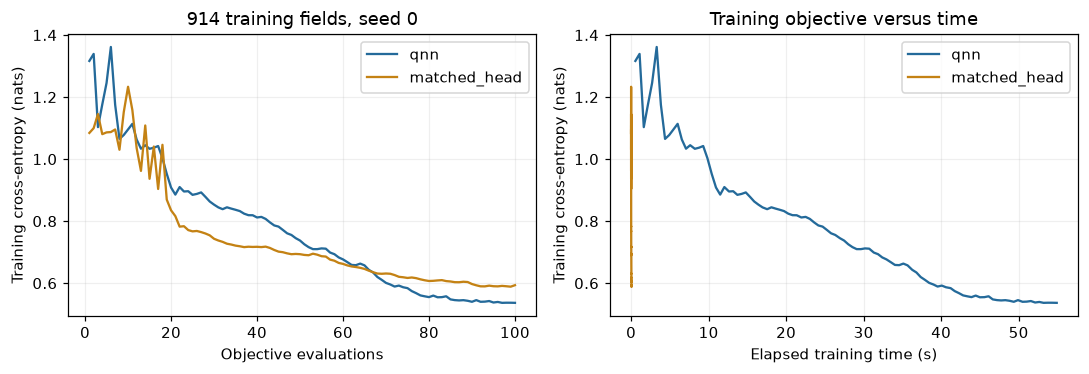

In [6]:
# Saved seed-0 training histories: objective versus evaluation count and wall time.
runs = json.loads((ROOT / 'results/runs.json').read_text())
summary = json.loads((ROOT / 'results/summary.json').read_text())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, color in [('qnn', '#246a9a'), ('matched_head', '#c48214')]:
    h = pd.DataFrame(json.loads((ROOT / f'results/{name}_0_history.json').read_text()))
    # Qiskit uses log2; the control uses natural log. Plot both in nats.
    if name == 'qnn': h['objective'] *= np.log(2)
    axes[0].plot(h.evaluation, h.objective, label=name, color=color)
    axes[1].plot(h.seconds, h.objective, label=name, color=color)
for ax in axes:
    ax.set_ylabel('Training cross-entropy (nats)'); ax.legend(); ax.grid(alpha=.2)
axes[0].set(xlabel='Objective evaluations', title='914 training fields, seed 0')
axes[1].set(xlabel='Elapsed training time (s)', title='Training objective versus time')
fig.tight_layout(); save_show(fig, '04_convergence')

In [7]:
from time import perf_counter

# Run your reps=2 model across seeds 0, 1, 2 on all 914 fields
runs = [r for r in runs if r['model'] != 'qnn_reps2']  # prevents duplicates if re-run

for seed in [0, 1, 2]:
    t0 = perf_counter()
    clf = QuantumClassifier(LABELS, encoding='ry', reps=2, max_evals=100)
    clf.fit(A[index], starter.target.to_numpy(), seed=seed)
    fit_sec = perf_counter() - t0

    t1 = perf_counter()
    preds = clf.predict(B)
    pred_sec = perf_counter() - t1

    runs.append({
        'model': 'qnn_reps2',
        'seed': seed,
        'metrics': score(validation.target, preds, LABELS),
        'fit_seconds': fit_sec,
        'predict_seconds': pred_sec,
        'preprocessing_seconds': 0.0,
        'resources': clf.resources(),
    })
    print(f"Seed {seed} done | macro-F1: {runs[-1]['metrics']['macro_f1']:.4f} | time: {fit_sec:.1f}s")

Seed 0 done | macro-F1: 0.8259 | time: 85.7s
Seed 1 done | macro-F1: 0.8094 | time: 88.4s
Seed 2 done | macro-F1: 0.8205 | time: 86.6s


In [8]:
from challenge.models import QuantumKernelClassifier

# Remove old quantum_kernel entries if you re-run this cell
runs = [r for r in runs if r['model'] != 'quantum_kernel']

for seed in [0, 1, 2]:
    t0 = perf_counter()
    qk = QuantumKernelClassifier(LABELS, C=0.25).fit(A[index], starter.target.to_numpy(), seed=seed)
    fit_sec = perf_counter() - t0

    t1 = perf_counter()
    preds = qk.predict(B)
    pred_sec = perf_counter() - t1

    runs.append({
        'model': 'quantum_kernel',
        'seed': seed,
        'metrics': score(validation.target, preds, LABELS),
        'fit_seconds': fit_sec,
        'predict_seconds': pred_sec,
        'preprocessing_seconds': 0.0,
        'resources': qk.resources(),
    })
    print(f"Quantum Kernel | Seed {seed} | macro-F1: {runs[-1]['metrics']['macro_f1']:.4f} | time: {fit_sec + pred_sec:.2f}s")

Quantum Kernel | Seed 0 | macro-F1: 0.8926 | time: 0.16s


c:\Users\Ahmed\Downloads\QiskitFallFest_EMSI_QuantumAfrica-main\QiskitFallFest_EMSI_QuantumAfrica-main\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Ahmed\Downloads\QiskitFallFest_EMSI_QuantumAfrica-main\QiskitFallFest_EMSI_QuantumAfrica-main\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Quantum Kernel | Seed 1 | macro-F1: 0.8926 | time: 0.14s
Quantum Kernel | Seed 2 | macro-F1: 0.8926 | time: 0.14s


c:\Users\Ahmed\Downloads\QiskitFallFest_EMSI_QuantumAfrica-main\QiskitFallFest_EMSI_QuantumAfrica-main\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


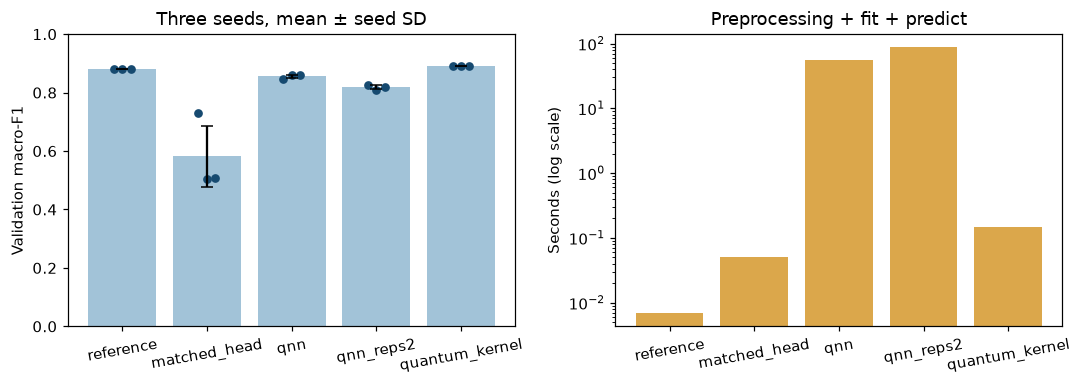

,model,mean_fit_predict_seconds,trainable,objective_evaluations,qubits,frozen_quantum,depth,two_qubit_gates,readout_group_sizes,encoding,compilation,reps,C
0,reference,0.006906,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,matched_head,0.051146,11.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,qnn,54.927574,8.0,100.0,4.0,0.0,6.0,3.0,"[6, 5, 5]",ry,logical decomposed H/P/RY/CX; no backend routing,NaN,NaN
3,qnn_reps2,87.040142,16.0,100.0,4.0,0.0,11.0,6.0,"[6, 5, 5]",ry,logical decomposed H/P/RY/CX; no backend routing,2.0,NaN
4,quantum_kernel,0.145803,0.0,NaN,4.0,NaN,1.0,0.0,NaN,ry_kernel,NaN,NaN,0.25


In [9]:
# Compare all three seeds; np.std() uses ddof=0 for these supplied summaries.
plot_models = ['reference', 'matched_head', 'qnn', 'qnn_reps2', 'quantum_kernel']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
resource_rows = []
for x, model in enumerate(plot_models):
    selected = [r for r in runs if r['model']==model]
    f1 = np.array([r['metrics']['macro_f1'] for r in selected])
    seconds = np.array([r['fit_seconds']+r['predict_seconds']+r['preprocessing_seconds'] for r in selected])
    axes[0].bar(x, f1.mean(), yerr=f1.std(), color='#a2c3d8', capsize=4)
    axes[0].scatter(x+np.linspace(-.1,.1,3), f1, color='#164a70', s=22)
    axes[1].bar(x, seconds.mean(), color='#dba74b')
    resource_rows.append({'model':model, **selected[0]['resources'], 'mean_fit_predict_seconds':seconds.mean()})
for ax in axes: ax.set_xticks(range(len(plot_models)), plot_models, rotation=10)
axes[0].set(ylabel='Validation macro-F1', ylim=(0,1), title='Three seeds, mean ± seed SD')
axes[1].set(ylabel='Seconds (log scale)', yscale='log', title='Preprocessing + fit + predict')  
fig.tight_layout(); save_show(fig, '06_performance_runtime')
resources = pd.DataFrame(resource_rows)
display(resources)
resources.to_csv(OUT / 'resources.csv', index=False)

## 4. Increase training coverage carefully

Use the same validation/test sets and all three classes. From a terminal in the repository root:

```bash
.venv/bin/python -m challenge.coverage check
.venv/bin/python -m challenge.coverage train --size 600 --results outputs/size600
.venv/bin/python -m challenge.coverage train --size 914 --results outputs/size914
.venv/bin/python -m challenge.coverage compare --baseline outputs/size600 --candidate outputs/size914
```

The training commands fit preprocessing on their selected rows, run seeds 0/1/2 and save validation scores, predictions and histories. Use `--size 100` or `200` for smaller checks. `comparison.json` reports changes in macro-F1, accuracy and each crop's recall, with paired spatial-bootstrap lower bounds. A bound below zero leaves possible loss unresolved; seed variation is a separate quantity.

**Beyond 914 fields:** request a checked extension preserving crop definitions, ±2-day dates and spatial independence. Do not duplicate rows, import unchecked source records or move evaluation fields into training. After receiving its `train.csv` and manifest:

```bash
.venv/bin/python -m challenge.coverage check --extension-dir /path/to/extension
.venv/bin/python -m challenge.coverage train --extension-dir /path/to/extension --results outputs/extended
.venv/bin/python -m challenge.coverage compare --baseline outputs/size914 --candidate outputs/extended
```

The source's >10,000 records span other crops, dates, regions and repeated observations; they are not all eligible fields. **More data does not guarantee better accuracy.** Inspect all classes, document any loss and freeze settings before final test prediction. See [coverage details](../docs/COVERAGE.md).

In [10]:
# Fast integrity check; success prints counts and file_checks="passed".
# The longer training commands above are optional and are not run by this cell.
import subprocess
subprocess.run([sys.executable, '-m', 'challenge.coverage', 'check'], cwd=ROOT, check=True)
learning = json.loads((ROOT / 'results/learning_curve_summary.json').read_text())

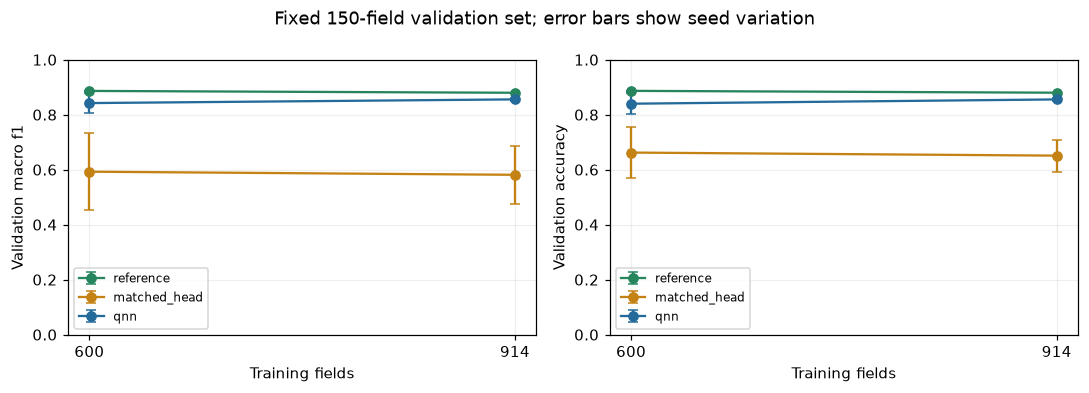

9275

In [11]:
# Plot the supplied size comparison on the identical 150 validation fields.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sizes = [600, 914]
models = ['reference', 'matched_head', 'qnn']
for model, color in zip(models, ['#26855d','#c48214','#246a9a']):
    rows = [next(r for r in learning['metrics'] if r['train']==size and r['model']==model)
            for size in sizes]
    for ax, metric in zip(axes, ['macro_f1','accuracy']):
        ax.errorbar(sizes, [r[metric+'_mean'] for r in rows],
                    yerr=[r[metric+'_sd'] for r in rows], marker='o', label=model, color=color, capsize=3)
        ax.set(xlabel='Training fields', ylabel='Validation '+metric.replace('_',' '), ylim=(0,1), xticks=sizes)
        ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.suptitle('Fixed 150-field validation set; error bars show seed variation')
fig.tight_layout(); save_show(fig, '07_expansion')
(OUT / 'expansion_summary.json').write_text(json.dumps(learning, indent=2))

**Read the learning curve:** from 600 to 914 fields, mean QNN macro-F1 rises from 0.8422 to 0.8557, while baseline macro-F1 falls slightly from 0.8865 to 0.8797. More training fields do not help every model. Error bars show three-seed variation, not confidence over new fields; inspect per-class recall before concluding that coverage helped.

For your next experiment, change one factor (encoding, depth, representation or training size), keep comparisons fair, and explain the result. You may instead build a quantum kernel or another hybrid. For stacking supervised model predictions, generate training predictions out of fold before fitting the combining model. See [method ideas](../docs/HINTS.md) and [evaluation requirements](../docs/EVALUATION.md).

## 5. Optional IBM inference only

Skip this section for the main challenge. To use a real device, install `requirements-hardware.txt`, set `QISKIT_IBM_TOKEN` in your environment, choose an available backend, and obtain permission to use the account and its execution quota before enabling the flags. Never put tokens in the notebook.

The helper submits **one inference using already-trained, fixed weights**. It does no hardware training or optimization. Its output includes backend, job ID, sampled probabilities and ideal probabilities; a single example is not a model accuracy estimate. Adapt `challenge/hardware.py` if your replacement model uses a different circuit/readout interface.

In [12]:
# Leave both flags False for ordinary local runs. Enable only for an authorized hardware job.
HARDWARE_ENABLED = False
HARDWARE_JOB_APPROVED = False
BACKEND_NAME = ''  # Set your inspected backend name before enabling hardware.
if HARDWARE_ENABLED:
    from challenge.hardware import infer_once
    result = infer_once(qnn, B[0], BACKEND_NAME, approved=HARDWARE_JOB_APPROVED, shots=512)
    display(result)
else:
    print('Hardware inference disabled; local task is complete.')

Hardware inference disabled; local task is complete.


## Which file should you change?

| File | How it works / when to edit |
| --- | --- |
| [`data.py`](../challenge/data.py) | Loads CSV/PCA files and checks hashes, schemas and split IDs. Keep these checks; put new train-fitted preprocessing in your experiment. |
| [`models.py`](../challenge/models.py) | Converts inputs to angles, builds the circuit, trains the QNN/control and returns predictions/resources. Edit encoding, architecture, optimizer or control here; you may replace either model. |
| [`classical.py`](../challenge/classical.py) | Builds StandardScaler → RBF-SVM from `configs/reference.json`. Preserve the supplied baseline; add comparisons separately. |
| [`metrics.py`](../challenge/metrics.py) | Scores every declared class and checks probability arrays. Reuse it unchanged for comparable metrics. |
| [`submission.py`](../challenge/submission.py) | Exposes the starter as `Submission`. Replace it with your final model, keeping `fit(X_train, y_train, seed)` and `predict(X)`; document preprocessing/input shape. |
| [`coverage.py`](../challenge/coverage.py) | Selects training subsets, fits preprocessing/models over three seeds and compares validation predictions by spatial bootstrap. Update model construction to benchmark your replacement. |
| [`hardware.py`](../challenge/hardware.py) | Binds trained weights, transpiles for the chosen backend and submits optional inference. Edit only if you need a device demonstration for a different model. |
| [`__init__.py`](../challenge/__init__.py) | Marks `challenge` as a Python package; no changes are needed. |

`configs/pilot.json` records starter settings; it is not read automatically. Change constructor arguments here and in the coverage/submission adapters as appropriate. If changing the input dimension, also update the model's four-input assumptions and its control. Restart the kernel after editing imported Python files, then run all cells.

For API details: [Qiskit functional circuit ansatz](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.real_amplitudes), [QNN classifier tutorial](https://stfc.github.io/qiskit-machine-learning/tutorials/02_neural_network_classifier_and_regressor.html), [exact sampler](https://stfc.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.primitives.QMLSampler.html). Use the pinned versions in `requirements.txt`.

**Finish:** run your selected model and control with seeds 0/1/2 on all training fields; report validation metrics, resource costs and limitations. Submit the runnable implementation and three to five slides as described in the [student brief](../Student_Challenge_Brief.pdf) and [README](../README.md).

In [13]:
for label, model_name in [('reps=1 (qnn)', 'qnn'), ('reps=2 (qnn_reps2)', 'qnn_reps2')]:
    selected = [r for r in runs if r['model'] == model_name]
    f1s = np.array([r['metrics']['macro_f1'] for r in selected])
    times = np.array([r['fit_seconds'] for r in selected])
    print(f"=== {label} ===")
    for r in selected:
        print(f"  Seed {r['seed']} | macro-F1: {r['metrics']['macro_f1']:.4f} | time: {r['fit_seconds']:.1f}s")
    print(f"  Mean macro-F1: {f1s.mean():.4f} ± {f1s.std():.4f} | Mean time: {times.mean():.1f}s\n")

=== reps=1 (qnn) ===
  Seed 0 | macro-F1: 0.8473 | time: 54.9s
  Seed 1 | macro-F1: 0.8586 | time: 54.8s
  Seed 2 | macro-F1: 0.8612 | time: 54.8s
  Mean macro-F1: 0.8557 ± 0.0060 | Mean time: 54.8s

=== reps=2 (qnn_reps2) ===
  Seed 0 | macro-F1: 0.8259 | time: 85.7s
  Seed 1 | macro-F1: 0.8094 | time: 88.4s
  Seed 2 | macro-F1: 0.8205 | time: 86.6s
  Mean macro-F1: 0.8186 ± 0.0069 | Mean time: 86.9s



In [14]:
from time import perf_counter
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from sklearn.svm import SVC
from challenge.models import angles

def ry_feature_map(n_qubits=4):
    qc = QuantumCircuit(n_qubits)
    x = ParameterVector('x', n_qubits)
    for i in range(n_qubits):
        qc.ry(x[i], i)
    return qc

feature_maps = {
    'RY (reps=1)': ry_feature_map(4),
    'ZZ (reps=1, linear)': zz_feature_map(4, reps=1, entanglement='linear'),
    'ZZ (reps=2, linear)': zz_feature_map(4, reps=2, entanglement='linear'),
}

X_tr_ang = angles(A[index])
X_va_ang = angles(B)
y_tr = starter.target.to_numpy()

for name, fm in feature_maps.items():
    t0 = perf_counter()
    S_tr = np.array([Statevector.from_instruction(fm.assign_parameters(x)).data for x in X_tr_ang])
    S_va = np.array([Statevector.from_instruction(fm.assign_parameters(x)).data for x in X_va_ang])
    K_tr = np.abs(S_tr @ S_tr.conj().T) ** 2
    K_va = np.abs(S_va @ S_tr.conj().T) ** 2
    kernel_time = perf_counter() - t0

    for C in [1.0, 10.0, 50.0, 100.0]:
        t1 = perf_counter()
        clf = SVC(kernel='precomputed', C=C).fit(K_tr, y_tr)
        preds = clf.predict(K_va)
        total_time = kernel_time + (perf_counter() - t1)
        res = score(validation.target, preds, LABELS)
        print(f"{name:20s} | C={C:5.1f} | macro-F1: {res['macro_f1']:.4f} | acc: {res['accuracy']:.4f} | time: {total_time:.2f}s")

RY (reps=1)          | C=  1.0 | macro-F1: 0.8716 | acc: 0.8733 | time: 0.14s
RY (reps=1)          | C= 10.0 | macro-F1: 0.8452 | acc: 0.8467 | time: 0.14s
RY (reps=1)          | C= 50.0 | macro-F1: 0.8524 | acc: 0.8533 | time: 0.14s
RY (reps=1)          | C=100.0 | macro-F1: 0.8461 | acc: 0.8467 | time: 0.14s
ZZ (reps=1, linear)  | C=  1.0 | macro-F1: 0.7894 | acc: 0.7867 | time: 0.30s
ZZ (reps=1, linear)  | C= 10.0 | macro-F1: 0.7743 | acc: 0.7733 | time: 0.31s
ZZ (reps=1, linear)  | C= 50.0 | macro-F1: 0.7597 | acc: 0.7600 | time: 0.32s
ZZ (reps=1, linear)  | C=100.0 | macro-F1: 0.7591 | acc: 0.7600 | time: 0.33s
ZZ (reps=2, linear)  | C=  1.0 | macro-F1: 0.7183 | acc: 0.7133 | time: 0.55s
ZZ (reps=2, linear)  | C= 10.0 | macro-F1: 0.7280 | acc: 0.7267 | time: 0.55s
ZZ (reps=2, linear)  | C= 50.0 | macro-F1: 0.7280 | acc: 0.7267 | time: 0.57s
ZZ (reps=2, linear)  | C=100.0 | macro-F1: 0.7285 | acc: 0.7267 | time: 0.57s


In [15]:
from sklearn.svm import SVC

fm = ry_feature_map(4)
S_tr = np.array([Statevector.from_instruction(fm.assign_parameters(x)).data for x in X_tr_ang])
S_va = np.array([Statevector.from_instruction(fm.assign_parameters(x)).data for x in X_va_ang])
K_tr = np.abs(S_tr @ S_tr.conj().T) ** 2
K_va = np.abs(S_va @ S_tr.conj().T) ** 2

for cw in [None, 'balanced']:
    for C in [0.1, 0.25, 0.5, 1.0, 2.0, 5.0]:
        clf = SVC(kernel='precomputed', C=C, class_weight=cw).fit(K_tr, y_tr)
        preds = clf.predict(K_va)
        res = score(validation.target, preds, LABELS)
        print(f"C={C:4.2f} | weight={str(cw):8s} | macro-F1: {res['macro_f1']:.4f} | acc: {res['accuracy']:.4f}")

C=0.10 | weight=None     | macro-F1: 0.8796 | acc: 0.8800
C=0.25 | weight=None     | macro-F1: 0.8926 | acc: 0.8933
C=0.50 | weight=None     | macro-F1: 0.8652 | acc: 0.8667
C=1.00 | weight=None     | macro-F1: 0.8716 | acc: 0.8733
C=2.00 | weight=None     | macro-F1: 0.8587 | acc: 0.8600
C=5.00 | weight=None     | macro-F1: 0.8587 | acc: 0.8600
C=0.10 | weight=balanced | macro-F1: 0.8781 | acc: 0.8800
C=0.25 | weight=balanced | macro-F1: 0.8716 | acc: 0.8733
C=0.50 | weight=balanced | macro-F1: 0.8644 | acc: 0.8667
C=1.00 | weight=balanced | macro-F1: 0.8707 | acc: 0.8733
C=2.00 | weight=balanced | macro-F1: 0.8707 | acc: 0.8733
C=5.00 | weight=balanced | macro-F1: 0.8707 | acc: 0.8733


In [16]:
import importlib, challenge.models
importlib.reload(challenge.models)
from challenge.models import QuantumKernelClassifier

qk = QuantumKernelClassifier(LABELS, C=0.25).fit(A[index], starter.target.to_numpy(), seed=0)
probs = qk.predict_proba(B[:5])

df_probs = pd.DataFrame(probs, columns=LABELS)
df_probs['predicted'] = qk.predict(B[:5])
df_probs['actual'] = validation.target.iloc[:5].to_numpy()
display(df_probs.round(3))

c:\Users\Ahmed\Downloads\QiskitFallFest_EMSI_QuantumAfrica-main\QiskitFallFest_EMSI_QuantumAfrica-main\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,alfalfa,maize,wheat,predicted,actual
0,0.012,0.004,0.984,wheat,wheat
1,0.008,0.785,0.207,maize,maize
2,0.013,0.773,0.214,maize,maize
3,0.016,0.903,0.081,maize,maize
4,0.010,0.931,0.059,maize,maize


In [17]:
from challenge.submission import Submission
sub = Submission().fit(A[index], starter.target.to_numpy(), seed=0)
print(score(validation.target, sub.predict(B), LABELS)['macro_f1'])

0.8925597049996261


c:\Users\Ahmed\Downloads\QiskitFallFest_EMSI_QuantumAfrica-main\QiskitFallFest_EMSI_QuantumAfrica-main\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [18]:
qk_metrics = [r for r in runs if r['model'] == 'quantum_kernel'][0]['metrics']
for k in ['macro_f1', 'accuracy', 'precision', 'recall', 'confusion']:
    print(f"{k}: {qk_metrics[k]}")

macro_f1: 0.8925597049996261
accuracy: 0.8933333333333333
precision: [0.9019607843137255, 0.8867924528301887, 0.8913043478260869]
recall: [0.92, 0.94, 0.82]
confusion: [[46, 1, 3], [1, 47, 2], [4, 5, 41]]
